# Session 13 — Reversible transformer: standard vs. midpoint vs. Euler vs. max batch

This notebook runs the same pipeline as `run_all.py`, one step per cell, so the
training logs and results stay next to the code that produced them.

1. **Gradcheck.** The hand-written reversible backward (midpoint and Euler) must match plain autograd in float64 before any run counts.
2. **`find_max_batch`** for the standard model gives `B_std`.
3. **Run 1:** standard model at `B_std`.
4. **Runs 2a/2b:** reversible midpoint and reversible Euler, both at `B_std`.
5. Pick the reversible variant with the lower final loss.
6. **`find_max_batch`** for that variant gives `B_max_rev`.
7. **Run 3:** the winning variant at `B_max_rev`.
8. Loss curves, memory, throughput and cost per 1M tokens.

Model: 10 layers, d_model 384, 6 heads, ~21M params, vocab 8192, seq 512, AdamW lr 4e-4, cosine, `dropout=0`, `weight_decay=0`.
Data: fixed 6M-token TinyStories slice (`data_tokens.bin`), same order for every run.

Everything this notebook writes goes to `notebook_run/` so it doesn't overwrite the `run_all.py` artifacts the README cites.

In [1]:
import os, sys, json, math, time, contextlib, subprocess
import torch
import matplotlib.pyplot as plt
%matplotlib inline

import train as T
import gradcheck as G

OUT = "notebook_run"
for d in ("logs", "figures", "results"):
    os.makedirs(f"{OUT}/{d}", exist_ok=True)

DATA_PATH = "data_tokens.bin"
TRAIN_TOKENS_TARGET = 6_000_000
GPU_PRICE_PER_HR = 0.176   # Colab T4 pay-as-you-go, see README "Cost comparison"

if not os.path.exists(DATA_PATH):
    # first run (e.g. fresh Colab): stream TinyStories + train the tokenizer
    subprocess.run([sys.executable, "prepare_data.py", "--n_tokens", str(TRAIN_TOKENS_TARGET)], check=True)

DEVICE = T.get_device()
print("torch      :", torch.__version__)
print("device     :", DEVICE)
print("data tokens:", os.path.getsize(DATA_PATH) // 2, "(uint16)")
print(f"config     : d_model={T.D_MODEL} n_head={T.N_HEAD} d_ff={T.D_FF} n_layer={T.N_LAYER} "
      f"seq_len={T.SEQ_LEN} vocab={T.VOCAB_SIZE} h={T.H_STEP} lr={T.LR}")

torch      : 2.14.0
device     : mps
data tokens: 6000000 (uint16)
config     : d_model=384 n_head=6 d_ff=1536 n_layer=10 seq_len=512 vocab=8192 h=0.25 lr=0.0004


### Logging helper

Every step below prints to the cell **and** is copied into `notebook_run/logs/<step>.log`, so the full log is also on disk.

In [2]:
class Tee:
    def __init__(self, *streams): self.streams = streams
    def write(self, s):
        for st in self.streams: st.write(s)
    def flush(self):
        for st in self.streams: st.flush()

@contextlib.contextmanager
def logged(name):
    with open(f"{OUT}/logs/{name}.log", "w") as f, contextlib.redirect_stdout(Tee(sys.stdout, f)):
        t0 = time.time()
        print(f"===== {name} =====")
        yield
        print(f"===== {name} finished in {time.time() - t0:.1f}s =====")

class Args:
    def __init__(self, **kw): self.__dict__.update(kw)

def train_run(name, mode, batch_size):
    with logged(name):
        return T.run(Args(mode=mode, data=DATA_PATH, batch_size=batch_size, max_steps=0,
                          log_every=20, log_csv=f"{OUT}/logs/{name}.csv"))

def find_max(name, mode):
    with logged(name):
        return T.find_max_batch(mode, DEVICE, seq_len=T.SEQ_LEN, start=8, max_cap=4096)

## Step 1 — Gradcheck: manual reversible backward vs. autograd

A 4-layer, d_model=8 toy model in **float64**. The reference keeps the full autograd graph; the manual path discards activations and recomputes them going backwards. Every parameter gradient has to match.

In [3]:
with logged("step1_gradcheck"):
    gc = {v: G.compare(v) for v in ("midpoint", "euler")}
    for v, ok in gc.items():
        print(f"[{'PASS' if ok else 'FAIL'}] gradcheck_{v}")
assert all(gc.values()), "gradcheck failed: don't trust any reversible run below"

===== step1_gradcheck =====

=== gradcheck: variant=midpoint ===


loss (reference autograd) = 3.6266570728
loss (manual reversible)  = 3.6266570728
loss diff = 0.00e+00
  OK   blocks.0.attn.proj.weight      max|diff|=1.301e-18
  OK   blocks.0.attn.qkv.weight       max|diff|=5.963e-19
  OK   blocks.0.ff.0.bias             max|diff|=1.626e-19
  OK   blocks.0.ff.0.weight           max|diff|=4.337e-19
  OK   blocks.0.ff.2.bias             max|diff|=1.344e-17
  OK   blocks.0.ff.2.weight           max|diff|=1.301e-18
  OK   blocks.0.ln1.bias              max|diff|=1.016e-20
  OK   blocks.0.ln1.weight            max|diff|=3.049e-20
  OK   blocks.0.ln2.bias              max|diff|=1.016e-20
  OK   blocks.0.ln2.weight            max|diff|=2.033e-20
  OK   blocks.1.attn.proj.weight      max|diff|=1.735e-18
  OK   blocks.1.attn.qkv.weight       max|diff|=6.505e-19
  OK   blocks.1.ff.0.bias             max|diff|=3.253e-19
  OK   blocks.1.ff.0.weight           max|diff|=5.421e-19
  OK   blocks.1.ff.2.bias             max|diff|=1.388e-17
  OK   blocks.1.ff.2.weight

## Step 2 — Largest batch for the **standard** model

Doubling search on synthetic batches, stopping at 75% of the device's recommended memory (MPS) or 90% of VRAM (CUDA), then backing off 15%.

In [4]:
B_STD = find_max("step2_find_max_batch_standard", "standard")
print("B_std =", B_STD)

===== step2_find_max_batch_standard =====
[find_max_batch] mode=standard device=mps memory_budget=10.73 GB cap=4096


  bs=    8 OK   mem=  3.58 GB   step_time= 1.25s


  bs=   16 OK   mem=  6.12 GB   step_time= 1.03s


  bs=   32 OK   mem= 11.26 GB   step_time= 2.41s


  -> memory budget reached (11.26 >= 10.73 GB); NOT counting bs=32 as safe, keeping last comfortably-fitting size
[find_max_batch] largest_ok=16 -> using 13 (15% safety margin)
===== step2_find_max_batch_standard finished in 8.3s =====
B_std = 13


## Step 3 — Run 1: standard model at `B_std`

In [5]:
run1 = train_run("run1_standard", "standard", B_STD)

===== run1_standard =====
[train] mode=standard device=mps batch_size=13
[train] 899 steps available, running 899 steps (5,983,744 loss-bearing tokens)


[train] model params: 21,072,384


  step     0/899 | loss 9.1014 | lr 2.35e-05 | tok/s      9330 | mem 5.341 GB | elapsed    0.7s


  step    20/899 | loss 6.5036 | lr 4.00e-04 | tok/s     13759 | mem 4.805 GB | elapsed   10.2s


  step    40/899 | loss 5.8597 | lr 3.99e-04 | tok/s     13925 | mem 4.805 GB | elapsed   19.6s


...

  step   820/899 | loss 4.3732 | lr 7.87e-06 | tok/s     13810 | mem 4.805 GB | elapsed  395.7s


  step   840/899 | loss 4.4489 | lr 4.40e-06 | tok/s     13816 | mem 4.805 GB | elapsed  405.2s


  step   860/899 | loss 4.8730 | lr 1.93e-06 | tok/s     13820 | mem 4.805 GB | elapsed  414.7s


  step   880/899 | loss 4.9684 | lr 4.58e-07 | tok/s     13823 | mem 4.805 GB | elapsed  424.2s


  step   898/899 | loss 4.5792 | lr 1.27e-09 | tok/s     13828 | mem 4.805 GB | elapsed  432.7s
[train] DONE {'mode': 'standard', 'batch_size': 13, 'seq_len': 512, 'n_params': 21072384, 'total_steps': 899, 'tokens_trained': 5983744, 'final_loss': 4.8008218765258786, 'tok_per_sec_overall': 13828.143819477935, 'tok_per_sec_steady': 13829.814134005, 'peak_mem_gb': 5.341495296, 'wall_clock_s': 432.72214102745056, 'device': 'mps'}
===== run1_standard finished in 433.3s =====


## Step 4a — Run 2a: reversible **midpoint** (leapfrog) at `B_std`

In [6]:
run2a = train_run("run2_reversible_midpoint", "reversible_midpoint", B_STD)

===== run2_reversible_midpoint =====
[train] mode=reversible_midpoint device=mps batch_size=13
[train] 899 steps available, running 899 steps (5,983,744 loss-bearing tokens)


[train] model params: 21,072,384


  step     0/899 | loss 9.0701 | lr 2.35e-05 | tok/s     10098 | mem 2.657 GB | elapsed    0.7s


  step    20/899 | loss 6.5609 | lr 4.00e-04 | tok/s     11947 | mem 2.657 GB | elapsed   11.7s


  step    40/899 | loss 6.1596 | lr 3.99e-04 | tok/s     11958 | mem 2.657 GB | elapsed   22.8s


...

  step   820/899 | loss 4.4551 | lr 7.87e-06 | tok/s     11589 | mem 2.657 GB | elapsed  471.6s


  step   840/899 | loss 4.5375 | lr 4.40e-06 | tok/s     11597 | mem 2.657 GB | elapsed  482.7s


  step   860/899 | loss 4.9406 | lr 1.93e-06 | tok/s     11599 | mem 2.657 GB | elapsed  494.1s


  step   880/899 | loss 5.0446 | lr 4.58e-07 | tok/s     11585 | mem 2.657 GB | elapsed  506.2s


  step   898/899 | loss 4.6816 | lr 1.27e-09 | tok/s     11591 | mem 2.657 GB | elapsed  516.2s
[train] DONE {'mode': 'reversible_midpoint', 'batch_size': 13, 'seq_len': 512, 'n_params': 21072384, 'total_steps': 899, 'tokens_trained': 5983744, 'final_loss': 4.886088409423828, 'tok_per_sec_overall': 11590.788008731102, 'tok_per_sec_steady': 11582.529629706152, 'peak_mem_gb': 2.657140736, 'wall_clock_s': 516.2499732971191, 'device': 'mps'}
===== run2_reversible_midpoint finished in 517.0s =====


## Step 4b — Run 2b: reversible **Euler** (two-stream RevNet) at `B_std`

In [7]:
run2b = train_run("run2_reversible_euler", "reversible_euler", B_STD)

===== run2_reversible_euler =====
[train] mode=reversible_euler device=mps batch_size=13


[train] 899 steps available, running 899 steps (5,983,744 loss-bearing tokens)


[train] model params: 21,072,384


  step     0/899 | loss 9.0594 | lr 2.35e-05 | tok/s     10494 | mem 2.657 GB | elapsed    0.6s


  step    20/899 | loss 6.5325 | lr 4.00e-04 | tok/s     11654 | mem 2.657 GB | elapsed   12.0s


...

  step   820/899 | loss 4.2550 | lr 7.87e-06 | tok/s     11927 | mem 2.657 GB | elapsed  458.2s


  step   840/899 | loss 4.3264 | lr 4.40e-06 | tok/s     11925 | mem 2.657 GB | elapsed  469.4s


  step   860/899 | loss 4.7734 | lr 1.93e-06 | tok/s     11927 | mem 2.657 GB | elapsed  480.5s


  step   880/899 | loss 4.8627 | lr 4.58e-07 | tok/s     11930 | mem 2.657 GB | elapsed  491.5s


  step   898/899 | loss 4.4367 | lr 1.27e-09 | tok/s     11933 | mem 2.657 GB | elapsed  501.5s
[train] DONE {'mode': 'reversible_euler', 'batch_size': 13, 'seq_len': 512, 'n_params': 21072384, 'total_steps': 899, 'tokens_trained': 5983744, 'final_loss': 4.682437152862549, 'tok_per_sec_overall': 11932.864790125754, 'tok_per_sec_steady': 11939.687075063684, 'peak_mem_gb': 2.657140736, 'wall_clock_s': 501.45075011253357, 'device': 'mps'}
===== run2_reversible_euler finished in 502.3s =====


## Step 5 — Pick the winning reversible variant (lower final loss; a non-finite loss loses)

In [8]:
candidates = [(n, r) for n, r in (("midpoint", run2a), ("euler", run2b)) if math.isfinite(r["final_loss"])]
WINNER = min(candidates, key=lambda nr: nr[1]["final_loss"])[0] if candidates else "midpoint"
WINNER_MODE = f"reversible_{WINNER}"
run2_winner = run2a if WINNER == "midpoint" else run2b
print(f"midpoint final loss = {run2a['final_loss']:.4f}")
print(f"euler    final loss = {run2b['final_loss']:.4f}")
print(f"standard final loss = {run1['final_loss']:.4f}  (reference)")
print(f"-> winner: {WINNER}")

midpoint final loss = 4.8861
euler    final loss = 4.6824
standard final loss = 4.8008  (reference)
-> winner: euler


## Step 6 — Largest batch for the winning reversible variant

In [9]:
B_MAX_REV = find_max(f"step6_find_max_batch_{WINNER}", WINNER_MODE)
print(f"B_max_rev = {B_MAX_REV}  vs  B_std = {B_STD}  ->  {B_MAX_REV / B_STD:.2f}x")

===== step6_find_max_batch_euler =====
[find_max_batch] mode=reversible_euler device=mps memory_budget=10.73 GB cap=4096


  bs=    8 OK   mem=  2.81 GB   step_time= 0.46s


  bs=   16 OK   mem=  2.98 GB   step_time= 0.79s


  bs=   32 OK   mem=  7.08 GB   step_time= 1.99s


  bs=   64 OK   mem= 11.47 GB   step_time= 3.26s


  -> memory budget reached (11.47 >= 10.73 GB); NOT counting bs=64 as safe, keeping last comfortably-fitting size
[find_max_batch] largest_ok=32 -> using 27 (15% safety margin)
===== step6_find_max_batch_euler finished in 9.4s =====
B_max_rev = 27  vs  B_std = 13  ->  2.08x


## Step 7 — Run 3: winning reversible variant at its max batch

In [10]:
run3 = train_run(f"run3_{WINNER}_maxbatch", WINNER_MODE, B_MAX_REV)

===== run3_euler_maxbatch =====
[train] mode=reversible_euler device=mps batch_size=27
[train] 433 steps available, running 433 steps (5,985,792 loss-bearing tokens)


[train] model params: 21,072,384


  step     0/433 | loss 9.0674 | lr 5.00e-05 | tok/s     11291 | mem 5.309 GB | elapsed    1.2s


  step    20/433 | loss 6.1953 | lr 3.99e-04 | tok/s     12434 | mem 5.307 GB | elapsed   23.3s


  step    40/433 | loss 5.9606 | lr 3.94e-04 | tok/s     12486 | mem 5.307 GB | elapsed   45.4s


...

  step   360/433 | loss 5.0755 | lr 2.84e-05 | tok/s     12495 | mem 5.307 GB | elapsed  399.4s


  step   380/433 | loss 5.0101 | lr 1.52e-05 | tok/s     12449 | mem 5.307 GB | elapsed  423.1s


  step   400/433 | loss 5.0785 | lr 5.92e-06 | tok/s     12452 | mem 5.307 GB | elapsed  445.2s


  step   420/433 | loss 5.1645 | lr 9.23e-07 | tok/s     12451 | mem 5.307 GB | elapsed  467.4s


  step   432/433 | loss 4.6630 | lr 5.46e-09 | tok/s     12452 | mem 5.307 GB | elapsed  480.7s
[train] DONE {'mode': 'reversible_euler', 'batch_size': 27, 'seq_len': 512, 'n_params': 21072384, 'total_steps': 433, 'tokens_trained': 5985792, 'final_loss': 4.851015481948853, 'tok_per_sec_overall': 12451.710595596824, 'tok_per_sec_steady': 12452.629573166987, 'peak_mem_gb': 5.30948096, 'wall_clock_s': 480.72045636177063, 'device': 'mps'}
===== run3_euler_maxbatch finished in 481.3s =====


## Step 8 — Results

In [11]:
def cost_per_m(tps): return (1e6 / tps) * (GPU_PRICE_PER_HR / 3600)

rows = [("1  standard", run1), ("2a midpoint", run2a), ("2b euler", run2b), (f"3  {WINNER} max-batch", run3)]
hdr = f"{'run':20s} {'batch':>5s} {'steps':>6s} {'tokens':>10s} {'final loss':>10s} {'tok/s':>9s} {'peak GB':>8s} {'wall s':>8s} {'$/1M tok':>10s}"
print(hdr); print("-" * len(hdr))
for name, r in rows:
    print(f"{name:20s} {r['batch_size']:5d} {r['total_steps']:6d} {r['tokens_trained']:10,d} "
          f"{r['final_loss']:10.4f} {r['tok_per_sec_steady']:9,.0f} {r['peak_mem_gb']:8.2f} "
          f"{r['wall_clock_s']:8.1f} {cost_per_m(r['tok_per_sec_steady']):10.6f}")

print()
print(f"memory at same batch ({B_STD}): standard {run1['peak_mem_gb']:.2f} GB vs reversible "
      f"{run2_winner['peak_mem_gb']:.2f} GB -> {run1['peak_mem_gb'] / run2_winner['peak_mem_gb']:.2f}x less")
print(f"max batch at same budget  : standard {B_STD} vs reversible {B_MAX_REV} -> {B_MAX_REV / B_STD:.2f}x")
print(f"speed cost at same batch  : {100 * (1 - run2_winner['tok_per_sec_steady'] / run1['tok_per_sec_steady']):.1f}% slower ({WINNER})")

run                  batch  steps     tokens final loss     tok/s  peak GB   wall s   $/1M tok
----------------------------------------------------------------------------------------------
1  standard             13    899  5,983,744     4.8008    13,830     5.34    432.7   0.003535
2a midpoint             13    899  5,983,744     4.8861    11,583     2.66    516.2   0.004221
2b euler                13    899  5,983,744     4.6824    11,940     2.66    501.5   0.004095
3  euler max-batch      27    433  5,985,792     4.8510    12,453     5.31    480.7   0.003926

memory at same batch (13): standard 5.34 GB vs reversible 2.66 GB -> 2.01x less
max batch at same budget  : standard 13 vs reversible 27 -> 2.08x
speed cost at same batch  : 13.7% slower (euler)


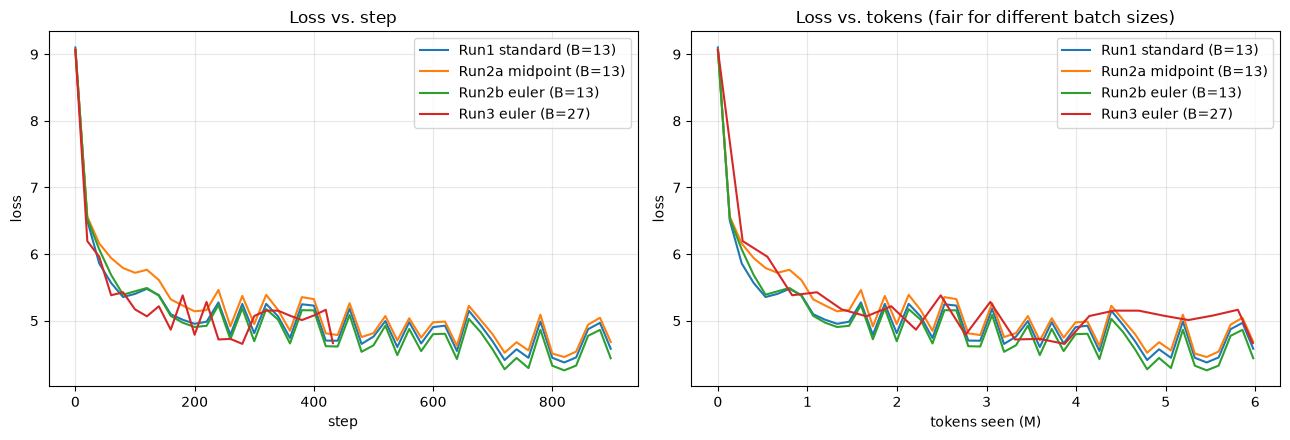

In [12]:
def read_csv(path):
    steps, losses = [], []
    with open(path) as f:
        next(f)
        for line in f:
            p = line.strip().split(",")
            steps.append(int(p[0])); losses.append(float(p[1]))
    return steps, losses

runs = [("run1_standard", f"Run1 standard (B={B_STD})"),
        ("run2_reversible_midpoint", f"Run2a midpoint (B={B_STD})"),
        ("run2_reversible_euler", f"Run2b euler (B={B_STD})"),
        (f"run3_{WINNER}_maxbatch", f"Run3 {WINNER} (B={B_MAX_REV})")]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for key, label in runs:
    s, l = read_csv(f"{OUT}/logs/{key}.csv")
    axes[0].plot(s, l, label=label)
    toks = [x * (B_MAX_REV if key.startswith("run3") else B_STD) * T.SEQ_LEN / 1e6 for x in s]
    axes[1].plot(toks, l, label=label)
axes[0].set(xlabel="step", ylabel="loss", title="Loss vs. step")
axes[1].set(xlabel="tokens seen (M)", ylabel="loss", title="Loss vs. tokens (fair for different batch sizes)")
for ax in axes: ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/figures/loss_curves.png", dpi=140); plt.show()

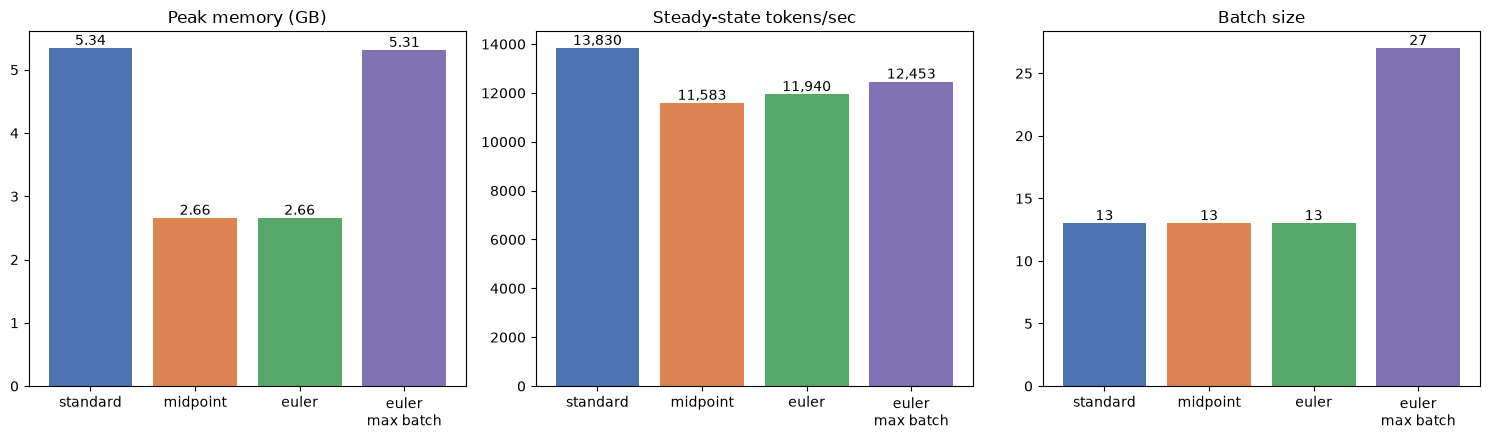

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
names = ["standard", "midpoint", "euler", f"{WINNER}\nmax batch"]
rs = [run1, run2a, run2b, run3]
colors = ["#4C72B0", "#DD8452", "#55A868", "#8172B3"]

for ax, key, title, fmt in [
    (axes[0], "peak_mem_gb", "Peak memory (GB)", "{:.2f}"),
    (axes[1], "tok_per_sec_steady", "Steady-state tokens/sec", "{:,.0f}"),
    (axes[2], "batch_size", "Batch size", "{}"),
]:
    vals = [r[key] for r in rs]
    ax.bar(names, vals, color=colors)
    ax.set_title(title)
    for i, v in enumerate(vals):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/memory_speed_batch.png", dpi=140); plt.show()

In [14]:
results = dict(
    device=DEVICE, b_std=B_STD, b_max_rev=B_MAX_REV, winner_variant=WINNER,
    gradcheck=gc, gpu_price_per_hr_assumed=GPU_PRICE_PER_HR,
    run1_standard=run1, run2_reversible_midpoint=run2a,
    run2_reversible_euler=run2b, run3_reversible_maxbatch=run3,
    cost_per_million_tokens_standard=cost_per_m(run1["tok_per_sec_steady"]),
    cost_per_million_tokens_reversible_maxbatch=cost_per_m(run3["tok_per_sec_steady"]),
)
with open(f"{OUT}/results/results.json", "w") as f:
    json.dump(results, f, indent=2)
print(f"wrote {OUT}/results/results.json")
print("logs:", sorted(os.listdir(f"{OUT}/logs")))

wrote notebook_run/results/results.json
logs: ['run1_standard.csv', 'run1_standard.log', 'run2_reversible_euler.csv', 'run2_reversible_euler.log', 'run2_reversible_midpoint.csv', 'run2_reversible_midpoint.log', 'run3_euler_maxbatch.csv', 'run3_euler_maxbatch.log', 'step1_gradcheck.log', 'step2_find_max_batch_standard.log', 'step6_find_max_batch_euler.log']


## Findings (from this run, Apple M3 Pro / MPS)

| Run | Variant | Batch | Steps | Final loss* | tok/s (steady) | Peak mem | $/1M tok |
|---|---|---|---|---|---|---|---|
| 1 | Standard | 13 | 899 | 4.801 | 13,830 | 5.34 GB | $0.00354 |
| 2a | Reversible midpoint | 13 | 899 | 4.886 | 11,583 | 2.66 GB | $0.00422 |
| 2b | Reversible Euler | 13 | 899 | **4.682** | 11,940 | 2.66 GB | $0.00410 |
| 3 | Reversible Euler, max batch | 27 | 433 | 4.851 | 12,453 | 5.31 GB | $0.00393 |

\* mean of the last 50 logged losses.

- **Correctness:** both reversible backwards match autograd in float64, with a max gradient difference of about 1e-16 (Step 1). A reversible backward with an indexing bug still trains, so this check is what makes the loss numbers trustworthy.
- **Variant that worked: Euler (two-stream RevNet coupling).** It had the lowest final loss of all four runs (4.682), below the standard baseline (4.801). Midpoint/leapfrog trained fine but finished higher (4.886).
- **Memory:** at the same batch size (13), reversible peaks at 2.66 GB vs 5.34 GB for standard, **2.01x less**, because it keeps no per-layer activations.
- **Max batch:** with the same 10.73 GB budget, reversible fits **27 vs 13, 2.08x** the batch.
- **Speed:** at the same batch, reversible is **13.7% slower** (11,940 vs 13,830 tok/s) because it recomputes each block during backward. At batch 27 it recovers to 12,453 tok/s.
- **Loss at max batch:** Run 3 sees the same ~6M tokens in half as many optimizer steps (433 vs 899), so its final loss (4.851) is higher than Run 2b's. A bigger batch buys parallelism, not better loss per token, unless the LR is retuned for it.
- These numbers agree with the earlier `run_all.py` run in the README to within run-to-run noise (e.g. standard 4.801 vs 4.801, Euler 4.682 vs 4.683).